In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
%%writefile -a /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


# ================= Phase 6: Privacy (identity leakage + adversarial de-identification) =================
from sklearn.preprocessing import StandardScaler as _SS
from sklearn.linear_model import LogisticRegression as _LR
from sklearn.ensemble import RandomForestClassifier as _RF
from sklearn.pipeline import make_pipeline as _pipe
from sklearn.metrics import accuracy_score as _acc


def within_subject_split(meta, val_frac=0.15, test_frac=0.25):
    """Chronological split INSIDE every (subject, gesture): early recordings = train,
    later = val/test. All 8 subjects appear in every split (needed to measure identity)."""
    m = meta[~meta['is_duplicate']].copy()
    m['_r'] = pd.to_numeric(m['recording_number'], errors='coerce')
    m = m.sort_values(['participant_id', 'label', '_r'], kind='stable')
    g = m.groupby(['participant_id', 'label'])
    frac = (g.cumcount() / g['label'].transform('size')).to_numpy()
    idx = m.index.to_numpy()
    return {'fold': 0,
            'train_idx': np.sort(idx[frac < 1 - val_frac - test_frac]),
            'val_idx': np.sort(idx[(frac >= 1 - val_frac - test_frac) & (frac < 1 - test_frac)]),
            'test_idx': np.sort(idx[frac >= 1 - test_frac])}


def identity_probe(F_tr, s_tr, F_te, s_te):
    """Post-hoc attacker: train a fresh classifier to predict WHO performed the gesture."""
    res = {}
    for name, clf in [('LR', _pipe(_SS(), _LR(max_iter=3000))),
                      ('RF', _RF(n_estimators=200, n_jobs=-1, random_state=SEED))]:
        clf.fit(F_tr, s_tr)
        res[name] = _acc(s_te, clf.predict(F_te))
    return res


class _GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x.view_as(x)

    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None


class AdvRadarCNN(nn.Module):
    """TinyRadarCNN + identity adversary.
    Only .net (the plain TinyRadarCNN) is deployed -> zero extra cost on the MCU."""
    def __init__(self, n_subjects, in_ch=3, widths=(16, 32, 64)):
        super().__init__()
        self.net = TinyRadarCNN(in_ch=in_ch, widths=widths)
        self.id_head = nn.Sequential(nn.Linear(widths[-1], 64), nn.ReLU(),
                                     nn.Linear(64, n_subjects))
        self.lam = 0.0
        self.mode = 'grl'      # 'grl' = gradient reversal, 'conf' = confusion (uniform) loss

    def forward(self, x):
        z = self.net.features(x).flatten(1)
        if self.mode == 'grl':
            return self.net.classifier(z), self.id_head(_GradReverse.apply(z, self.lam)), None
        frozen = {k: v.detach() for k, v in self.id_head.named_parameters()}
        conf = torch.func.functional_call(self.id_head, frozen, (z,))
        return self.net.classifier(z), self.id_head(z.detach()), conf


@torch.no_grad()
def embed(net, X, bs=512, level='embedding'):
    """What an attacker could see: 64-d embedding (GAP output) or 12-d output logits."""
    net.eval()
    f = (lambda b: net.features(b).flatten(1)) if level == 'embedding' else net
    return torch.cat([f(X[s:s + bs]) for s in range(0, len(X), bs)]).cpu().numpy()


def train_adv_fold(Xc, y, subj, fold, device, lam=1.0, widths=(16, 32, 64),
                   channels=(0, 1, 2), epochs=60, patience=15, min_epochs=20,
                   batch_size=64, lr=1e-3, seed=None, mode='grl'):
    """Gesture training with subject-adversarial de-identification.
    mode='grl': gradient reversal (DANN); mode='conf': push identity predictions to uniform.
    lam=0 -> normal training (adversary has no influence on the features).
    Model selection only from epoch >= min_epochs, when the adversary ramp is ~fully on."""
    seed = SEED if seed is None else seed
    set_seed(seed + fold['fold'])
    tr, va, te = fold['train_idx'], fold['val_idx'], fold['test_idx']
    _, s_tr = np.unique(subj[tr], return_inverse=True)

    xtr = prepare_input(Xc, tr, 'persample', channels)
    mean, std = xtr.mean(axis=(0, 1, 2)), xtr.std(axis=(0, 1, 2))
    to_t = lambda x: torch.tensor(np.transpose((x - mean) / std, (0, 3, 1, 2)),
                                  dtype=torch.float32, device=device)
    Xtr = to_t(xtr); del xtr
    Xva = to_t(prepare_input(Xc, va, 'persample', channels))
    Xte = to_t(prepare_input(Xc, te, 'persample', channels))
    ytr = torch.tensor(y[tr], device=device)
    str_ = torch.tensor(s_tr, device=device)

    model = AdvRadarCNN(int(s_tr.max()) + 1, in_ch=len(channels), widths=widths).to(device)
    model.mode = mode
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ce = nn.CrossEntropyLoss()

    best_f1, best_ep, best_state, bad = -1.0, 0, None, 0
    for ep in range(1, epochs + 1):
        p = (ep - 1) / epochs
        model.lam = lam * (2.0 / (1.0 + np.exp(-10 * p)) - 1.0)     # DANN ramp-up
        model.train()
        perm = torch.randperm(len(Xtr), device=device)
        for s in range(0, len(perm), batch_size):
            b = perm[s:s + batch_size]
            if len(b) < 2:
                continue
            g_out, id_out, conf = model(Xtr[b])
            loss = ce(g_out, ytr[b]) + ce(id_out, str_[b])
            if conf is not None:
                loss = loss - model.lam * torch.log_softmax(conf, 1).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()
        if ep < min_epochs:
            continue
        val_f1 = evaluate(y[va], predict(model.net, Xva))['macro_f1']
        if val_f1 > best_f1:
            best_f1, best_ep, bad = val_f1, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(best_state)
    net = model.net.eval()
    return {'net': net, 'y_pred': predict(net, Xte), 'val_f1': best_f1,
            'best_epoch': best_ep, 'last_epoch': ep, 'mean': mean, 'std': std,
            'emb_train': embed(net, Xtr), 'emb_test': embed(net, Xte),
            'logit_train': embed(net, Xtr, level='logits'),
            'logit_test': embed(net, Xte, level='logits')}

Appending to /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


In [2]:
import sys, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, '/content/drive/MyDrive/RadarGestureEdgeAI')
import radar_utils as ru
importlib.reload(ru)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)
Xc, y, meta = ru.load_compact()
print("Xc:", Xc.shape)

Device: cpu
Xc: (9593, 90, 32, 3)


Train 5636 | Val 1409 | Test 2348 | subjects in test: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] | chance = 12.8%
Training gesture model (CPU, ~10-20 min)...
Gesture F1 (within-subject test) = 96.0  | best epoch 24 | 7.1 min
1. Raw radar (block features)        -> identity acc 98.7%
2. Compact input (block features)    -> identity acc 80.7%
3. CNN embedding (64-d)              -> identity acc 58.9%
4. Output logits (12-d)              -> identity acc 47.8%
5. Gesture label only (on-device)    -> identity acc 13.4%

===== IDENTITY LEAKAGE AUDIT (who is the user? 8 subjects) =====
                            stage  dim  attacker_LR_%  attacker_RF_%  leakage_%  chance_%
    1. Raw radar (block features)  729           89.0           98.7       98.7      12.8
2. Compact input (block features)  648           69.2           80.7       80.7      12.8
          3. CNN embedding (64-d)   64           44.7           58.9       58.9   

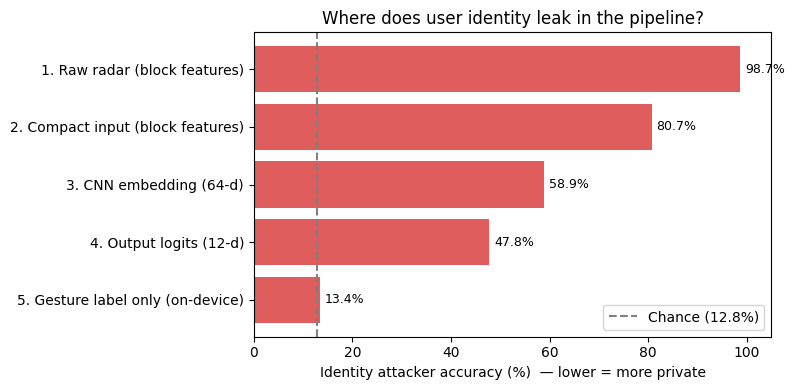

Total time: 9.1 min


In [12]:
import time
t0 = time.time()

subj = meta['participant_id'].to_numpy()
split = ru.within_subject_split(meta)
tr, te = split['train_idx'], split['test_idx']
s_tr, s_te = subj[tr], subj[te]
chance = pd.Series(s_te).value_counts(normalize=True).max() * 100
print(f"Train {len(tr)} | Val {len(split['val_idx'])} | Test {len(te)} | "
      f"subjects in test: {sorted(set(s_te))} | chance = {chance:.1f}%", flush=True)

# Gesture model trained on ALL 8 subjects (early recordings), normal training (lam = 0)
# CPU-light setting (GPU quota exhausted) -> rerun later on GPU with default 60 epochs
print("Training gesture model (CPU, ~10-20 min)...", flush=True)
r = ru.train_adv_fold(Xc, y, subj, split, DEVICE, lam=0.0,
                      epochs=25, min_epochs=15, patience=6)
gest_f1 = ru.evaluate(y[te], r['y_pred'])['macro_f1'] * 100
print(f"Gesture F1 (within-subject test) = {gest_f1:.1f}  | best epoch {r['best_epoch']} "
      f"| {(time.time() - t0) / 60:.1f} min", flush=True)

F_raw = np.load(ru.PROJECT / 'processed' / 'features_blocks_raw.npy')
F_cmp = np.load(ru.PROJECT / 'processed' / 'features_blocks_compact.npy')
onehot = lambda logits: np.eye(ru.NUM_CLASSES)[logits.argmax(1)]
stages = [
    ('1. Raw radar (block features)',     F_raw[tr], F_raw[te]),
    ('2. Compact input (block features)', F_cmp[tr], F_cmp[te]),
    ('3. CNN embedding (64-d)',           r['emb_train'], r['emb_test']),
    ('4. Output logits (12-d)',           r['logit_train'], r['logit_test']),
    ('5. Gesture label only (on-device)', onehot(r['logit_train']), onehot(r['logit_test'])),
]
rows = []
for name, F_tr, F_te in stages:
    acc = ru.identity_probe(F_tr, s_tr, F_te, s_te)
    rows.append({'stage': name, 'dim': F_tr.shape[1],
                 'attacker_LR_%': round(acc['LR'] * 100, 1),
                 'attacker_RF_%': round(acc['RF'] * 100, 1),
                 'leakage_%': round(max(acc.values()) * 100, 1)})
    print(f"{name:36s} -> identity acc {rows[-1]['leakage_%']:.1f}%", flush=True)
leak = pd.DataFrame(rows)
leak['chance_%'] = round(chance, 1)
print("\n===== IDENTITY LEAKAGE AUDIT (who is the user? 8 subjects) =====")
print(leak.to_string(index=False))
ru.save_results(leak, 'table_identity_leakage_cpu_preview')

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(leak.stage[::-1], leak['leakage_%'][::-1], color='tab:red', alpha=0.75)
ax.axvline(chance, ls='--', color='gray', label=f'Chance ({chance:.1f}%)')
for i, v in enumerate(leak['leakage_%'][::-1]):
    ax.text(v + 1, i, f"{v:.1f}%", va='center', fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel('Identity attacker accuracy (%)  — lower = more private')
ax.set_title('Where does user identity leak in the pipeline?')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_identity_leakage_cpu_preview.png', dpi=200)
plt.show()
print(f"Total time: {(time.time() - t0) / 60:.1f} min")

none lam=0.0 : loaded from Drive
grl  lam=0.3 : loaded from Drive
grl  lam=1.0 : loaded from Drive
grl  lam=3.0 : training (CPU, ~8-10 min)...
   -> gesture F1 95.7 | leak emb 56.6% | leak logits 37.9% | 8.1 min
grl  lam=10.0: training (CPU, ~8-10 min)...
   -> gesture F1 94.8 | leak emb 59.5% | leak logits 40.1% | 8.2 min
conf lam=1.0 : loaded from Drive

===== PRIVACY-UTILITY SWEEP (within-subject split, chance = 12.8%) =====
mode  lam  gesture_F1  leak_embedding_%  leak_logits_%  best_epoch
none  0.0        96.0              58.9           47.8          24
 grl  0.3        95.8              55.7           41.5          23
 grl  1.0        96.2              55.2           41.2          24
conf  1.0        96.4              56.6           42.8          24
 grl  3.0        95.7              56.6           37.9          24
 grl 10.0        94.8              59.5           40.1          24
Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/table_privacy_sweep_e25.csv


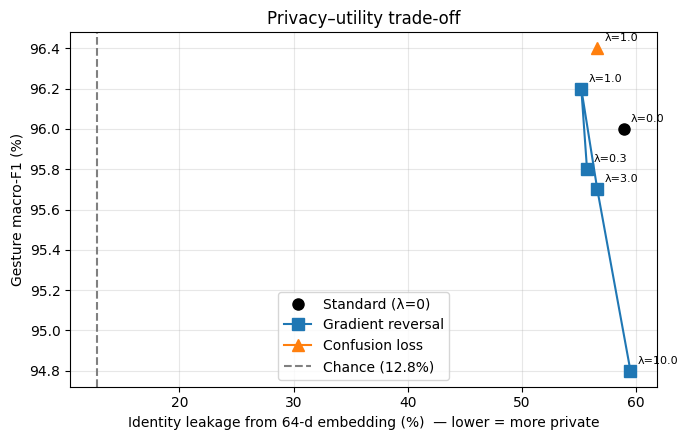

In [4]:
import time
TRAIN = dict(epochs=25, min_epochs=15, patience=6)        # same recipe as Cell 4 (CPU)

subj = meta['participant_id'].to_numpy()
split = ru.within_subject_split(meta)
tr, te = split['train_idx'], split['test_idx']
s_tr, s_te = subj[tr], subj[te]
chance = pd.Series(s_te).value_counts(normalize=True).max() * 100

configs = [('none', 0.0),
           ('grl', 0.3), ('grl', 1.0), ('grl', 3.0), ('grl', 10.0),
           ('conf', 1.0)]
                             # confusion loss
sweep_path = ru.PROJECT / 'results' / 'privacy_sweep_e25.csv'
done = pd.read_csv(sweep_path) if sweep_path.exists() else pd.DataFrame()

for mode, lam in configs:
    if len(done) and ((done['mode'] == mode) & (done['lam'] == lam)).any():
        print(f"{mode:4s} lam={lam:<4}: loaded from Drive")
        continue
    print(f"{mode:4s} lam={lam:<4}: training (CPU, ~8-10 min)...", flush=True)
    t0 = time.time()
    r = ru.train_adv_fold(Xc, y, subj, split, DEVICE, lam=lam,
                          mode='grl' if mode == 'none' else mode, **TRAIN)
    emb = ru.identity_probe(r['emb_train'], s_tr, r['emb_test'], s_te)
    lgt = ru.identity_probe(r['logit_train'], s_tr, r['logit_test'], s_te)
    row = {'mode': mode, 'lam': lam,
           'gesture_F1': round(ru.evaluate(y[te], r['y_pred'])['macro_f1'] * 100, 1),
           'leak_embedding_%': round(max(emb.values()) * 100, 1),
           'leak_logits_%': round(max(lgt.values()) * 100, 1),
           'best_epoch': r['best_epoch']}
    done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
    done.to_csv(sweep_path, index=False)                   # saved after every run
    print(f"   -> gesture F1 {row['gesture_F1']:.1f} | leak emb {row['leak_embedding_%']:.1f}% | "
          f"leak logits {row['leak_logits_%']:.1f}% | {(time.time() - t0) / 60:.1f} min", flush=True)

print(f"\n===== PRIVACY-UTILITY SWEEP (within-subject split, chance = {chance:.1f}%) =====")
print(done.to_string(index=False))
ru.save_results(done, 'table_privacy_sweep_e25')

names = {'none': 'Standard (λ=0)', 'grl': 'Gradient reversal', 'conf': 'Confusion loss'}
styles = {'none': ('black', 'o'), 'grl': ('tab:blue', 's'), 'conf': ('tab:orange', '^')}
fig, ax = plt.subplots(figsize=(7, 4.5))
for mode, g in done.groupby('mode', sort=False):
    c, m = styles[mode]
    g = g.sort_values('lam')
    ax.plot(g['leak_embedding_%'], g['gesture_F1'], marker=m, color=c, ms=8,
            ls='-' if mode != 'none' else '', label=names[mode])
    for _, q in g.iterrows():
        ax.annotate(f"λ={q['lam']}", (q['leak_embedding_%'], q['gesture_F1']),
                    textcoords='offset points', xytext=(5, 5), fontsize=8)
ax.axvline(chance, ls='--', color='gray', label=f'Chance ({chance:.1f}%)')
ax.set_xlabel('Identity leakage from 64-d embedding (%)  — lower = more private')
ax.set_ylabel('Gesture macro-F1 (%)')
ax.set_title('Privacy–utility trade-off')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_privacy_utility_e25.png', dpi=200)
plt.show()

===== MEMORY (ST Edge AI Core, INT8) =====
model    MACC  weights_KiB  activations_KiB  flash_total_KiB  model_RAM_KiB  system_RAM_KB
    M 7886716        24.16            25.56             45.6           28.0           66.2
    S 2302916         6.48            15.28             27.5           17.6           55.8

===== MEASURED LATENCY ON REAL STM32 BOARDS =====
model            board       core  MHz  latency_ms  MAC_per_cycle  our_estimate_ms
    M   NUCLEO-H743ZI2  Cortex-M7  480       22.92           0.72             20.3
    M STM32H747I-DISCO  Cortex-M7  480       27.63           0.59              NaN
    M    STM32H7B3I-DK  Cortex-M7  280       39.61           0.71              NaN
    M STM32F769I-DISCO  Cortex-M7  216       50.74           0.72              NaN
    M    STM32H573I-DK Cortex-M33  250       66.32           0.48              NaN
    M STM32F469I-DISCO  Cortex-M4  180      106.80           0.41              NaN
    S   NUCLEO-H743ZI2  Cortex-M7  480        9.80  

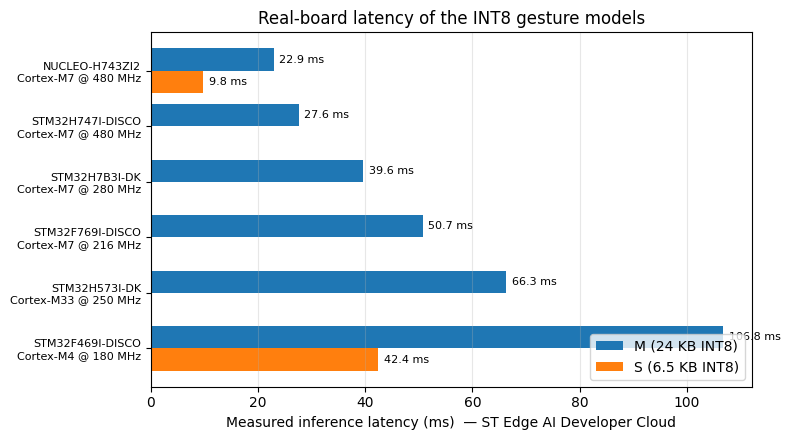

In [5]:
# ===== Step 5.4: real-board results from ST Edge AI Developer Cloud (Core 4.1.0, balanced) =====
WINDOW_KB, PRE_KB = 33.8, 4.4          # compact window buffer + streaming pre-processing (Step 5.3)
st_mem = pd.DataFrame([
    {'model': 'M', 'MACC': 7886716, 'weights_KiB': 24.16, 'activations_KiB': 25.56,
     'flash_total_KiB': round(46730 / 1024, 1), 'model_RAM_KiB': round(28672 / 1024, 1)},
    {'model': 'S', 'MACC': 2302916, 'weights_KiB': 6.48, 'activations_KiB': 15.28,
     'flash_total_KiB': round(28136 / 1024, 1), 'model_RAM_KiB': round(18060 / 1024, 1)},
])
st_mem['system_RAM_KB'] = (st_mem.model_RAM_KiB + WINDOW_KB + PRE_KB).round(1)
print("===== MEMORY (ST Edge AI Core, INT8) =====")
print(st_mem.to_string(index=False))

lat = pd.DataFrame([
    ('M', 'NUCLEO-H743ZI2',   'Cortex-M7',  480,  22.92),
    ('M', 'STM32H747I-DISCO', 'Cortex-M7',  480,  27.63),
    ('M', 'STM32H7B3I-DK',    'Cortex-M7',  280,  39.61),
    ('M', 'STM32F769I-DISCO', 'Cortex-M7',  216,  50.74),
    ('M', 'STM32H573I-DK',    'Cortex-M33', 250,  66.32),
    ('M', 'STM32F469I-DISCO', 'Cortex-M4',  180, 106.80),
    ('S', 'NUCLEO-H743ZI2',   'Cortex-M7',  480,   9.80),
    ('S', 'STM32F469I-DISCO', 'Cortex-M4',  180,  42.42),
], columns=['model', 'board', 'core', 'MHz', 'latency_ms'])
macc = dict(zip(st_mem.model, st_mem.MACC))
lat['MAC_per_cycle'] = (lat.model.map(macc) / (lat.latency_ms * 1e-3 * lat.MHz * 1e6)).round(2)

est = pd.read_csv(ru.PROJECT / 'results' / 'table_mcu_estimates.csv')
est_h7 = est[est.MCU == 'STM32H743'].set_index('model')['latency_ms']
lat['our_estimate_ms'] = np.where(lat.board == 'NUCLEO-H743ZI2', lat.model.map(est_h7), np.nan)
print("\n===== MEASURED LATENCY ON REAL STM32 BOARDS =====")
print(lat.to_string(index=False))
ru.save_results(st_mem, 'table_st_memory')
ru.save_results(lat, 'table_st_latency')

piv = lat.pivot(index='board', columns='model', values='latency_ms').sort_values('M')
cores = lat.drop_duplicates('board').set_index('board')
labels = [f"{b}\n{cores.loc[b, 'core']} @ {cores.loc[b, 'MHz']} MHz" for b in piv.index]
yy = np.arange(len(piv))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(yy - 0.2, piv['M'], height=0.4, label='M (24 KB INT8)', color='tab:blue')
ax.barh(yy + 0.2, piv['S'], height=0.4, label='S (6.5 KB INT8)', color='tab:orange')
for i, (m, s) in enumerate(zip(piv['M'], piv['S'])):
    ax.text(m + 1, i - 0.2, f"{m:.1f} ms", va='center', fontsize=8)
    if not np.isnan(s):
        ax.text(s + 1, i + 0.2, f"{s:.1f} ms", va='center', fontsize=8)
ax.set_yticks(yy)
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Measured inference latency (ms)  — ST Edge AI Developer Cloud')
ax.set_title('Real-board latency of the INT8 gesture models')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_st_latency.png', dpi=200)
plt.show()